# Task 1 - Exploratory Data Analysis: Titanic Passengers
Public dataset: Titanic (891 passengers). Goal: clean the data, visualize it, and document actionable observations.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200})
df = pd.read_csv("data/titanic.csv")
def save(name): plt.savefig(f"figures/{name}.png", bbox_inches="tight")
print(df.shape); df.dtypes

(891, 12)


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

## 1. Summary profiling

In [2]:
display(df.describe(include='all').T.round(2))
miss = df.isna().sum(); miss = pd.DataFrame({'missing': miss, 'pct': (miss/len(df)*100).round(1)}); miss[miss.missing>0]

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


,missing,pct
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


**Observation:** `Cabin` is ~77% missing, `Age` ~20% missing, `Embarked` only 2 rows. The treatment must differ by column.

## 2. Cleaning (with justification)
- **Cabin (77% missing):** dropped. Imputing >70% of a column would invent most of its values; instead we keep a binary flag `HasCabin` (cabin records existed mostly for first class).
- **Age (20% missing):** imputed with the **median Age per (Pclass, Sex)** group. Age is right-skewed, so the median is more robust than the mean, and group medians preserve the class/sex age differences.
- **Embarked (2 rows):** filled with the **mode**; with 0.2% missing the effect is negligible.
- **Duplicates:** removed if present.
- **Outliers:** detected with the 1.5xIQR rule; `Fare` outliers are real (first-class suites), so they are **kept** and a log transform is used for plotting.

In [3]:
df['HasCabin'] = df.Cabin.notna().astype(int)
df = df.drop(columns='Cabin')
df['Age'] = df.groupby(['Pclass','Sex']).Age.transform(lambda s: s.fillna(s.median()))
df['Embarked'] = df.Embarked.fillna(df.Embarked.mode()[0])
print('Duplicates removed:', df.duplicated().sum()); df = df.drop_duplicates()
print('Remaining nulls:', int(df.isna().sum().sum()))
for c in ['Age','Fare']:
    q1,q3 = df[c].quantile([.25,.75]); iqr=q3-q1
    n = ((df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr)).sum()
    print(f'{c}: {n} IQR outliers ({n/len(df):.1%})')

Duplicates removed: 0
Remaining nulls: 0
Age: 33 IQR outliers (3.7%)
Fare: 116 IQR outliers (13.0%)


## 3. Feature distributions

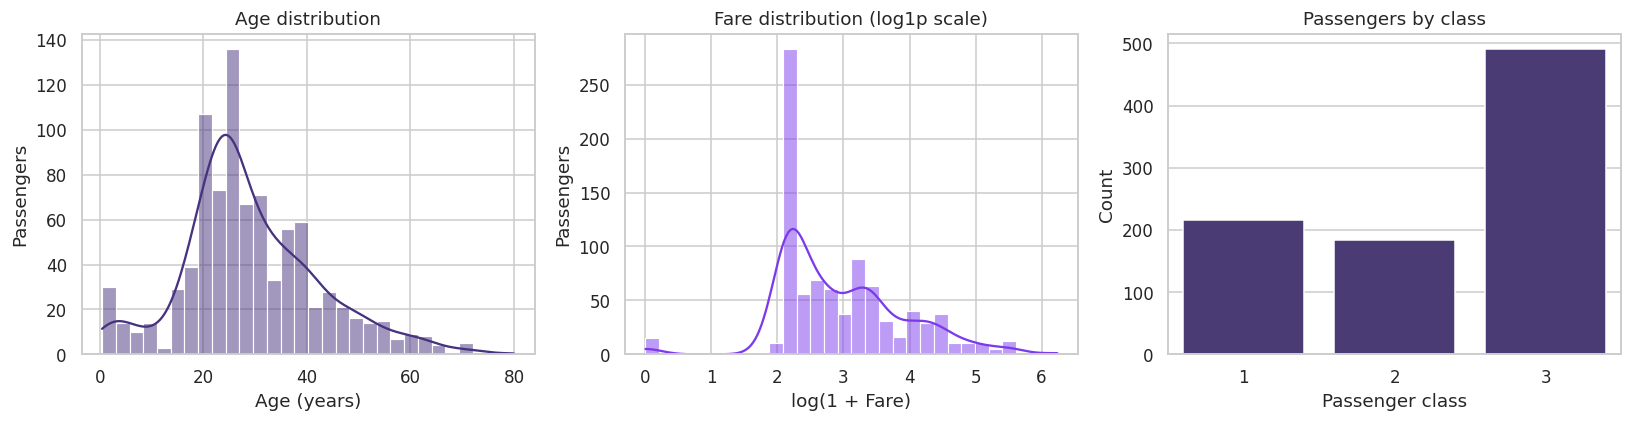

In [4]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.histplot(df.Age, bins=30, kde=True, ax=ax[0]); ax[0].set(title='Age distribution', xlabel='Age (years)', ylabel='Passengers')
sns.histplot(np.log1p(df.Fare), bins=30, kde=True, ax=ax[1], color='#7c3aed'); ax[1].set(title='Fare distribution (log1p scale)', xlabel='log(1 + Fare)', ylabel='Passengers')
sns.countplot(data=df, x='Pclass', ax=ax[2]); ax[2].set(title='Passengers by class', xlabel='Passenger class', ylabel='Count')
plt.tight_layout(); save('distributions'); plt.show()

**Takeaway:** Age is roughly bell-shaped with a spike of young children; Fare is heavily right-skewed (hence the log scale); third class holds more than half of all passengers, so any overall statistic is dominated by third-class behavior.

## 4. Boxplots (outliers & group differences)

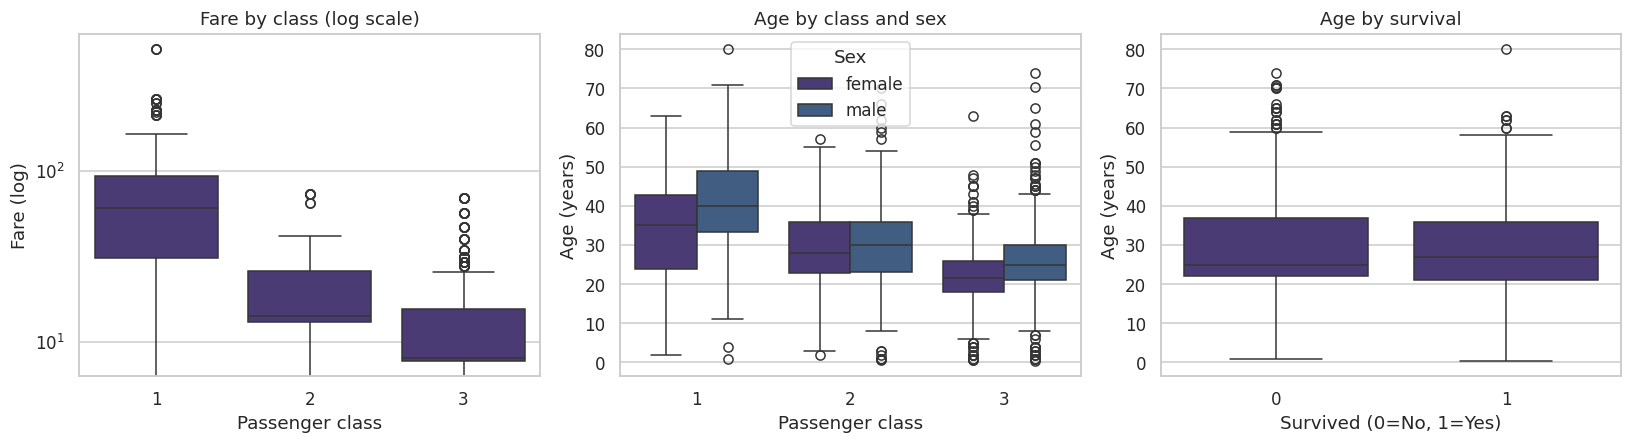

In [5]:
fig, ax = plt.subplots(1,3, figsize=(15,4.2))
sns.boxplot(data=df, x='Pclass', y='Fare', ax=ax[0]); ax[0].set_yscale('log'); ax[0].set(title='Fare by class (log scale)', xlabel='Passenger class', ylabel='Fare (log)')
sns.boxplot(data=df, x='Pclass', y='Age', hue='Sex', ax=ax[1]); ax[1].set(title='Age by class and sex', xlabel='Passenger class', ylabel='Age (years)')
sns.boxplot(data=df, x='Survived', y='Age', ax=ax[2]); ax[2].set(title='Age by survival', xlabel='Survived (0=No, 1=Yes)', ylabel='Age (years)')
plt.tight_layout(); save('boxplots'); plt.show()

**Takeaway:** median fare rises sharply with class and first class contains the extreme fares (genuine, so kept). Passengers get older as class improves. Survivors and non-survivors have similar median age; age alone is a weak signal.

## 5. Survival drivers

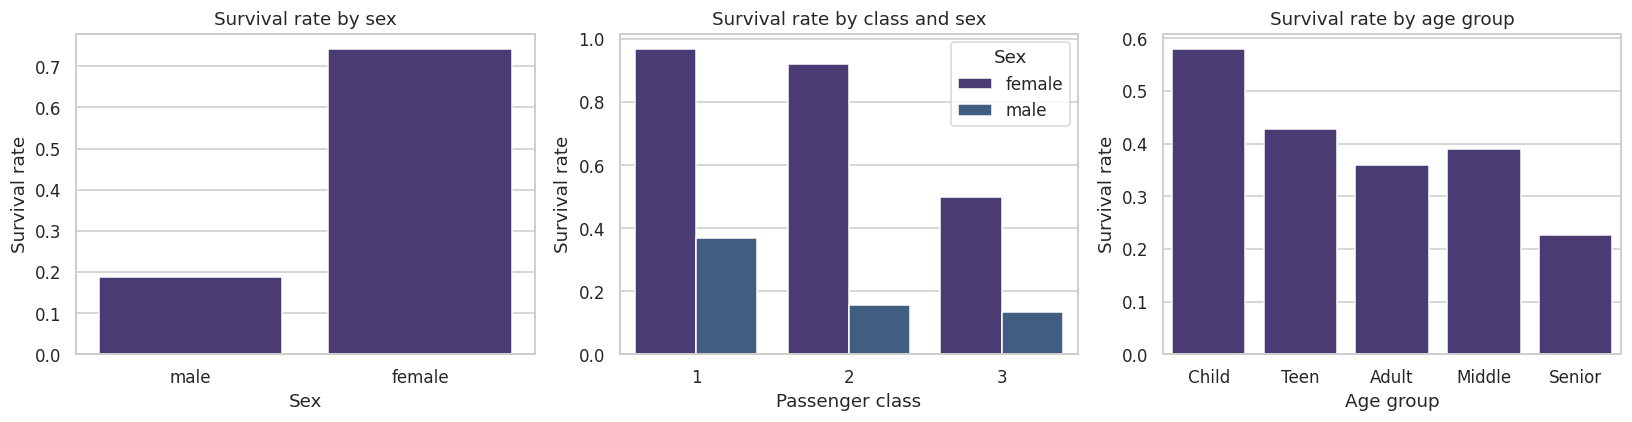

{'female': 0.742, 'male': 0.189} {1: 0.63, 2: 0.473, 3: 0.242}


In [6]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.barplot(data=df, x='Sex', y='Survived', ax=ax[0], errorbar=None); ax[0].set(title='Survival rate by sex', ylabel='Survival rate')
sns.barplot(data=df, x='Pclass', y='Survived', hue='Sex', ax=ax[1], errorbar=None); ax[1].set(title='Survival rate by class and sex', xlabel='Passenger class', ylabel='Survival rate')
df['AgeGroup'] = pd.cut(df.Age, [0,12,18,40,60,100], labels=['Child','Teen','Adult','Middle','Senior'])
sns.barplot(data=df, x='AgeGroup', y='Survived', ax=ax[2], errorbar=None); ax[2].set(title='Survival rate by age group', xlabel='Age group', ylabel='Survival rate')
plt.tight_layout(); save('survival_rates'); plt.show()
print(df.groupby('Sex').Survived.mean().round(3).to_dict(), df.groupby('Pclass').Survived.mean().round(3).to_dict())

**Takeaways:** women survived at roughly 4x the rate of men; survival falls steadily from first to third class, and the class gradient holds *within* each sex. Children had the best survival odds. Practical implication: a model or policy analysis must account for sex and class jointly, not separately.

## 6. Correlation heatmap and pairwise scatter plots

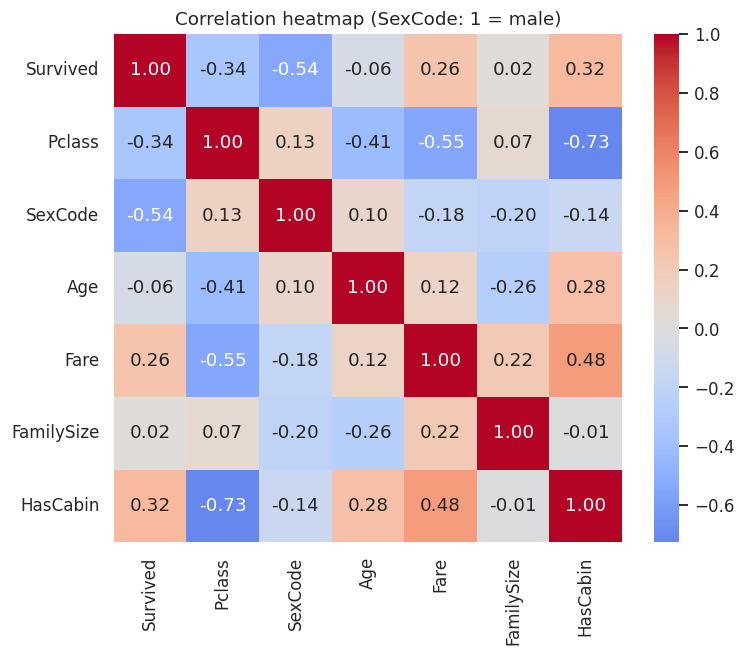

In [7]:
d = df.copy(); d['SexCode'] = (d.Sex=='male').astype(int); d['FamilySize'] = d.SibSp + d.Parch + 1
corr = d[['Survived','Pclass','SexCode','Age','Fare','FamilySize','HasCabin']].corr()
plt.figure(figsize=(7.5,6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation heatmap (SexCode: 1 = male)'); save('correlation_heatmap'); plt.show()

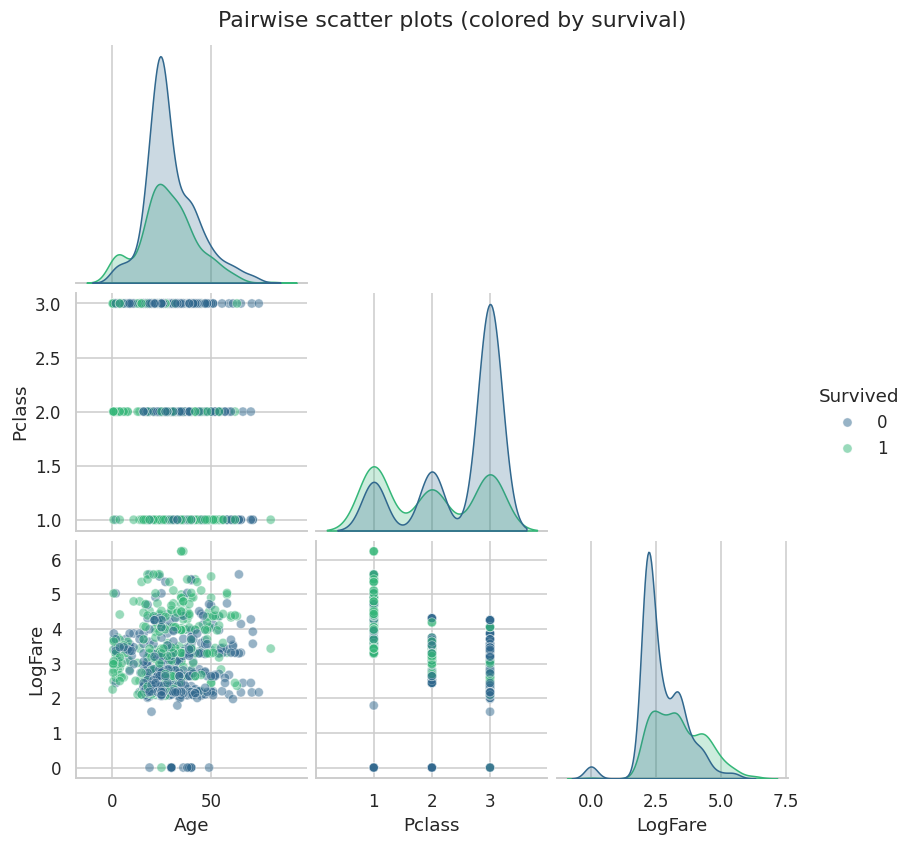

In [8]:
g = sns.pairplot(d[['Survived','Age','Fare','Pclass']].assign(LogFare=np.log1p(d.Fare)).drop(columns='Fare'), hue='Survived', palette='viridis', corner=True, plot_kws={'alpha':.5})
g.figure.suptitle('Pairwise scatter plots (colored by survival)', y=1.02); g.savefig('figures/pairplot.png', dpi=150); plt.show()

**Takeaways:** the strongest correlations with survival are `SexCode` (about -0.54, men less likely), `Pclass` (about -0.34) and `Fare`/`HasCabin` (positive, but they largely proxy for class). `Pclass` and `Fare` are strongly related, so using both in a linear model risks multicollinearity.

## 7. Key findings
1. Sex was the strongest survival factor, followed by passenger class.
2. Fare and HasCabin carry mostly the same information as class.
3. Missingness is informative: a missing Cabin mostly meant a lower-class passenger.
4. Family size has a non-linear effect (small families did better than solo travelers or very large families).
5. Limitations: data is observational, one ship, and group-median imputation slightly reduces Age variance.